# 06. Stability and risk insights

**The question this notebook answers:** do the patterns we found hold up over time, which differences in default rate are real rather than chance, do the factors tell us anything the platform's own grade does not, and which fields should we refuse to use for fairness reasons?

**What the brief asks:**
1. Compare **2013 and 2014** loans for key fields and factor scores using the **Population Stability Index (PSI)** and flag anything that drifts.
2. Show **default rate across factor-score deciles and key segments with 95% confidence intervals**, and use a **significance test** (chi-square or Mann-Whitney) before calling a difference real. **Compare the factors with the platform's grade:** what do they add?
3. Discuss whether **`zip_code` or `addr_state` could act as a proxy for protected characteristics**, and recommend how to treat them.
4. Explain in **one paragraph** how training only on accepted loans limits the findings.

**Terms used in this notebook**
- **PSI:** how much a field's distribution moved between two groups of loans. Under 0.1 stable, 0.1 to 0.25 moderate shift, 0.25 or more major shift.
- **95% confidence interval (Wilson):** the range a default rate could plausibly take given how many loans are in the group. A rate from 50 loans has a wide interval; from 5,000 loans, a narrow one.
- **Significance test:** how likely a difference this large is if there were truly no difference. A small p-value (under 0.05) means chance is an unlikely explanation. **Chi-square** compares rates between groups; **Mann-Whitney** compares the scores of defaulters and non-defaulters; **Cochran-Armitage** tests for a steady rise or fall across ordered groups.
- **Holm correction:** when many tests are run, some will look significant by luck. Holm tightens the threshold to account for the number of tests.

In [1]:
import os, json
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")

import numpy as np
import pandas as pd
from IPython.display import Image, display
from scipy.stats import mannwhitneyu
from sklearn.metrics import roc_auc_score
from statsmodels.stats.multitest import multipletests

from credit_risk.io import FIT_CUTOFF
from credit_risk.psi import categorical_psi, label, numeric_psi, psi_from_shares
from credit_risk.stats import cochran_armitage_trend, level_vs_rest, rate_table, wilson_interval

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)

ds = pd.read_parquet("contract/analytical_dataset.parquet")
ds["issue_d"] = pd.to_datetime(ds.issue_d)
ds["year"] = ds.issue_d.dt.year
fit = ds[ds.issue_d <= FIT_CUTOFF]
FACTORS = [c for c in ds.columns if c.startswith("factor_")]
print(f"{len(ds):,} loans; {len(fit):,} in the fit window; {len(FACTORS)} factor scores")

30,000 loans; 14,373 in the fit window; 8 factor scores


## 1. Stability: do 2013 and 2014 look alike? (bullet 1)

### A worked example of PSI
Suppose a field falls into three bins. The share of loans in each bin was 50%, 30%, 20% in 2013 and is 40%, 30%, 30% in 2014. PSI adds up, over bins, `(new share - old share) x ln(new share / old share)`:

In [2]:
old, new = [0.5, 0.3, 0.2], [0.4, 0.3, 0.3]
parts = [(n - o) * np.log(n / o) for o, n in zip(old, new)]
print("contribution of each bin:", np.round(parts, 4), "  -> PSI =", round(sum(parts), 4), f"({label(sum(parts))})")
assert abs(sum(parts) - psi_from_shares(old, new)) < 1e-12

contribution of each bin: [0.0223 0.     0.0405]   -> PSI = 0.0629 (stable)


**Reading it.** A shift of ten points of loans between bins gives PSI of about 0.06: stable. The measure grows quickly with bigger shifts, which is what makes it a useful alarm. Bin edges are set on the *earlier* year, as they would be in monitoring.

### On the real fields

In [3]:
y13, y14, y15 = (ds[ds.year == y] for y in (2013, 2014, 2015))
rows = []
for c in FACTORS:
    rows.append({"field": c, "PSI 2013 vs 2014": numeric_psi(y13[c], y14[c])})
for c in ["fico_mid_treated", "dti_treated", "annual_inc_log", "loan_amnt_log", "revol_util_treated", "int_rate"]:
    rows.append({"field": c, "PSI 2013 vs 2014": numeric_psi(y13[c], y14[c])})
for c in ["term", "grade", "home_ownership_group", "purpose_group", "verification_status"]:
    rows.append({"field": c, "PSI 2013 vs 2014": categorical_psi(y13[c], y14[c])})
live = pd.DataFrame(rows).sort_values("PSI 2013 vs 2014", ascending=False)
live["reading"] = live["PSI 2013 vs 2014"].map(label)
print(live.round(3).to_string(index=False))

                        field  PSI 2013 vs 2014        reading
          verification_status             0.232 moderate shift
                     int_rate             0.070         stable
             fico_mid_treated             0.038         stable
                        grade             0.031         stable
        factor_public_records             0.031         stable
           revol_util_treated             0.024         stable
factor_recent_account_opening             0.020         stable
                  dti_treated             0.017         stable
                loan_amnt_log             0.017         stable
         factor_account_count             0.017         stable
 factor_revolving_utilization             0.013         stable
 factor_revolving_credit_size             0.013         stable
       factor_credit_capacity             0.009         stable
             factor_loan_size             0.009         stable
           factor_debt_burden             0.006        

all 44 fields and category sets checked: {'stable': 42, 'major shift': 1, 'moderate shift': 1}

the ones that are not stable (2013 vs 2014), and what they look like a year later:
              field     kind  psi_2013_vs_2014  psi_2014_vs_2015 reading_2013_vs_2014 reading_2014_vs_2015
          job_group category             6.297             0.003          major shift               stable
verification_status category             0.232             0.004       moderate shift               stable

moved between 2014 and 2015:
   field  psi_2014_vs_2015 reading_2014_vs_2015
int_rate             0.192       moderate shift


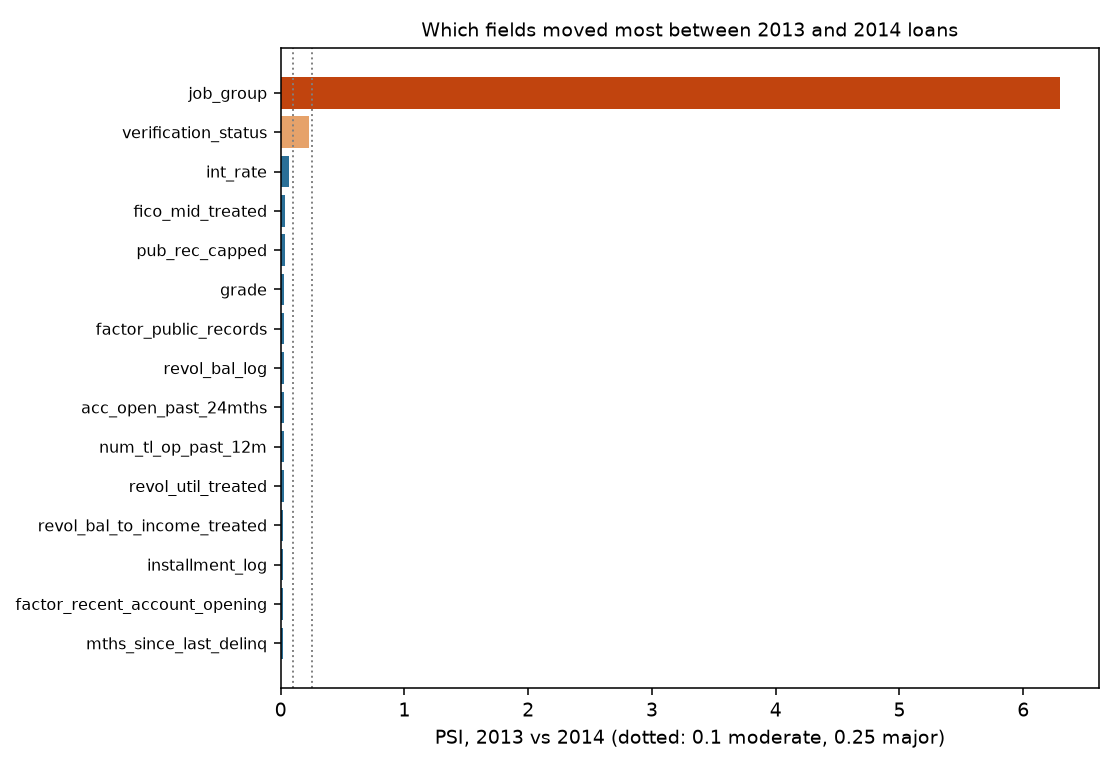

In [4]:
psi = pd.read_csv("reports/a6_stability_psi/tables/psi_by_field.csv")
print(f"all {len(psi)} fields and category sets checked: {psi.reading_2013_vs_2014.value_counts().to_dict()}")
print("\nthe ones that are not stable (2013 vs 2014), and what they look like a year later:")
print(psi[psi.reading_2013_vs_2014 != "stable"].round(3).to_string(index=False))
print("\nmoved between 2014 and 2015:")
print(psi[psi.reading_2014_vs_2015 != "stable"][["field", "psi_2014_vs_2015", "reading_2014_vs_2015"]].round(3).to_string(index=False))
display(Image("reports/a6_stability_psi/figures/psi_2013_vs_2014.png", width=760))

**Reading it.** **42 of the 44 fields and category sets are stable**, including all eight factor scores (0.006 to 0.031), so the factors describe 2014 applicants the way they describe 2013 ones. Two are flagged, and each has a different explanation:

- **`job_group` (PSI 6.3): a data change, not a population change.** The title field changed meaning in October 2013 (employer names before, job titles after; notebook 04). Compared within the valid period the PSI is small (below).
- **`verification_status` (0.23, moderate): a real policy change.** The platform changed how it verifies applicants (below). The field stays a candidate input but is **flagged for monitoring**, because its link with default may not survive a policy that keeps moving.

Between 2014 and 2015 only the platform's own **`int_rate`** moves (PSI 0.19, moderate): the platform changed how it prices. That is one more reason not to build the model on the interest rate.

In [5]:
job = ds.job_group
print("job_group, all of 2013 vs 2014        :", round(categorical_psi(job[ds.year == 2013], job[ds.year == 2014]), 2))
valid = (ds.issue_d >= "2013-10-01") & (ds.year == 2013)
print("job_group, Oct-Dec 2013 vs 2014        :", round(categorical_psi(job[valid], job[ds.year == 2014]), 3))
half = ds.year.astype(str) + (ds.issue_d.dt.month > 6).map({False: " H1", True: " H2"})
print("\nverification_status, share of loans by half-year (%):")
print((pd.crosstab(half, ds.verification_status, normalize="index") * 100).round(0).to_string())

job_group, all of 2013 vs 2014        : 6.3
job_group, Oct-Dec 2013 vs 2014        : 0.015

verification_status, share of loans by half-year (%):
verification_status  Not Verified  Source Verified  Verified
row_0                                                       
2013 H1                      32.0             15.0      52.0
2013 H2                      27.0             27.0      47.0
2014 H1                      27.0             43.0      31.0
2014 H2                      33.0             41.0      27.0
2015 H1                      28.0             44.0      27.0
2015 H2                      26.0             43.0      31.0


**Reading it.** Inside the valid period the job groups are stable (PSI about 0.015), so the repair worked. The verification mix shows a genuine policy shift: "Verified" falls from about half of loans in 2013 to under a third from 2014, while "Source Verified" grows from 15% to over 40%. The 'Not Verified' share stays roughly constant (27% to 33%), so the platform did not verify fewer applicants; it changed *how* it verifies, replacing full verification by source verification. Nothing in the applicants changed.

## 2. Default rate by factor-score decile (bullet 2)

A **decile** cuts the loans into ten equal groups from the lowest factor score to the highest. If a factor carries risk information, the default rate should climb or fall steadily across the ten groups. We test that with a trend test and a Mann-Whitney test, and correct for testing eight factors at once.

                factor  default rate, decile 1  default rate, decile 10  trend z  trend p  Mann-Whitney p  AUC alone  Holm-adjusted trend p
recent_account_opening                  0.0974                   0.2629  13.7536   0.0000          0.0000     0.5879                 0.0000
           debt_burden                  0.1113                   0.2225  10.6094   0.0000          0.0000     0.5685                 0.0000
 revolving_utilization                  0.1224                   0.2149   9.4563   0.0000          0.0000     0.5606                 0.0000
       credit_capacity                  0.1947                   0.1050  -9.2705   0.0000          0.0000     0.5588                 0.0000
             loan_size                  0.1293                   0.2232   7.0808   0.0000          0.0000     0.5464                 0.0000
 revolving_credit_size                  0.2114                   0.1328  -5.3883   0.0000          0.0000     0.5349                 0.0000
        public_recor

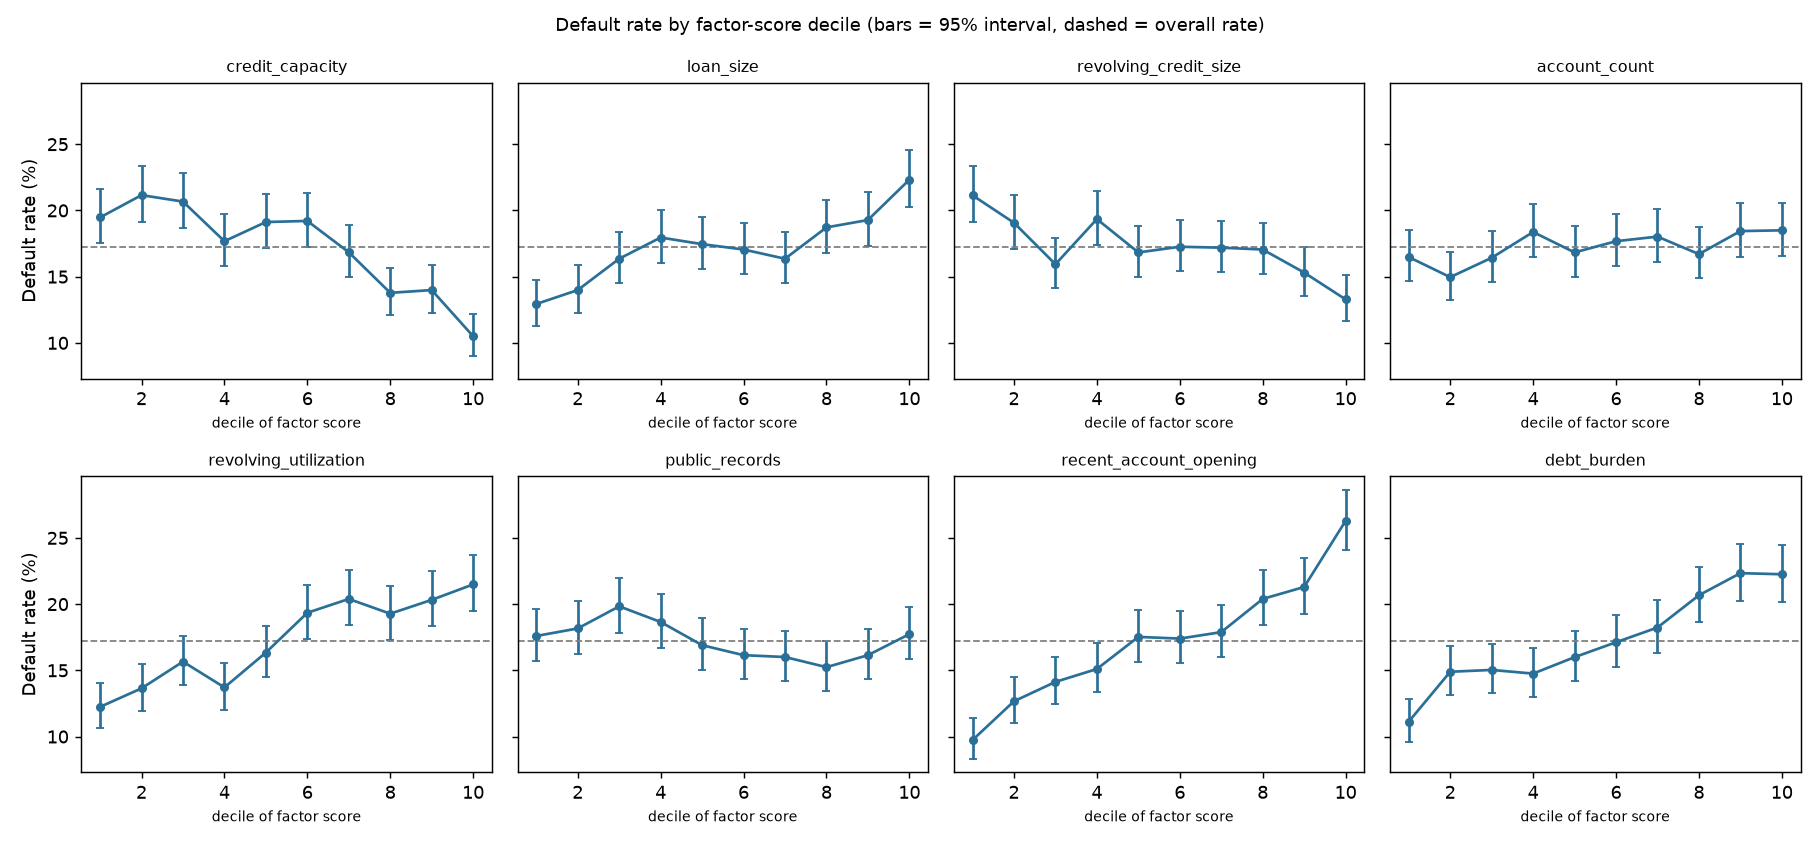

In [6]:
rows, per_decile = [], {}
y = fit.defaulted.to_numpy()
for c in FACTORS:
    dec = pd.qcut(fit[c], 10, labels=False, duplicates="drop") + 1
    t = rate_table(fit.assign(decile=dec), "decile")
    per_decile[c] = t
    z, p_trend = cochran_armitage_trend(t.decile, t.defaults, t.loans)
    mw = mannwhitneyu(fit.loc[fit.defaulted == 1, c], fit.loc[fit.defaulted == 0, c]).pvalue
    auc = roc_auc_score(y, fit[c])
    rows.append({"factor": c.replace("factor_", ""), "default rate, decile 1": t.rate.iloc[0], "default rate, decile 10": t.rate.iloc[-1],
                 "trend z": z, "trend p": p_trend, "Mann-Whitney p": mw, "AUC alone": max(auc, 1 - auc)})
res = pd.DataFrame(rows)
res["Holm-adjusted trend p"] = multipletests(res["trend p"], method="holm")[1]
print(res.sort_values("trend z", key=abs, ascending=False).round(4).to_string(index=False))
display(Image("reports/a6_deciles_and_segments/figures/default_rate_by_factor_decile.png", width=900))

**Reading it.** Six factors show a clear, steady trend in the direction credit logic expects, with Holm-adjusted p-values below 0.001:
- *more* recent account opening, debt burden, revolving utilisation and loan size go with *higher* default (for recent account opening the rate climbs from about 10% in the lowest decile to 26% in the highest);
- *more* credit capacity and larger revolving limits go with *lower* default.

`account_count` and `public_records` are statistically detectable (Holm p about 0.03) but **practically negligible**: the decile rates span only 2.0 and 0.1 percentage points. A p-value says whether an effect is real; it does not say whether it is large. **We do not claim these two separate risk.** The decile charts carry 95% intervals, so the reader can see where neighbouring deciles are indistinguishable.

## 3. Default rate by segment, with a rule against small groups (bullet 2)

A segment can look dramatic purely because it is small. The rule we apply: **a level is called a real difference only if it has at least 300 loans and its test against all other loans survives Holm correction within that segmentation.** Otherwise the finding is "no clear difference" or "too few loans to say". A worked example:

In [7]:
t = rate_table(fit, "home_ownership_group")
t["p vs all other loans"] = level_vs_rest(t.defaults, t.loans)
t["Holm p"] = multipletests(t["p vs all other loans"], method="holm")[1]
t["enough loans (300+)"] = t.loans >= 300
print(t.round(4).to_string(index=False))

home_ownership_group  loans  defaults   rate  ci_low  ci_high  p vs all other loans  Holm p  enough loans (300+)
            MORTGAGE   7407      1137 0.1535  0.1455   0.1619                0.0000  0.0000                 True
                 OWN   1406       240 0.1707  0.1519   0.1913                0.8582  0.8582                 True
                RENT   5560      1101 0.1980  0.1878   0.2087                0.0000  0.0000                 True


**Reading it.** Mortgage holders (15.4%) default less and renters (19.8%) more than the rest, with non-overlapping intervals and Holm p-values far below 0.05. `OWN` (17.1%) is not clearly different from the rest: its interval straddles the average. The same procedure gives the full picture:

In [8]:
seg = pd.read_csv("reports/a6_deciles_and_segments/tables/default_rate_by_segment.csv")
print(pd.read_csv("reports/a6_deciles_and_segments/tables/segment_overall_tests.csv").round(4).to_string(index=False))
show = seg[seg.segment.isin(["term", "grade", "home_ownership_group", "verification_status"])]
print("\n" + show[["segment", "level", "loans", "rate", "ci_low", "ci_high", "holm_p", "verdict"]].round(3).to_string(index=False))

             segment  levels  levels_with_enough_loans  chi_square_p_across_levels  highest_rate  lowest_rate
                term       2                         2                      0.0000        0.2827       0.1324
               grade       7                         6                      0.0000        0.3818       0.0449
       purpose_group       6                         5                      0.0000        0.1997       0.1458
home_ownership_group       3                         3                      0.0000        0.1980       0.1535
 verification_status       3                         3                      0.0000        0.1930       0.1271
     emp_length_band       4                         4                      0.0003        0.1953       0.1547
         income_band       5                         5                      0.0000        0.2134       0.1317
           loan_band       5                         5                      0.0000        0.2012       0.1405
          

states: 32 levels; 17 have at least 300 loans
verdict
no clear difference     17
too few loans to say    15

job groups:
verdict
no clear difference          10
real: safer than the rest     1


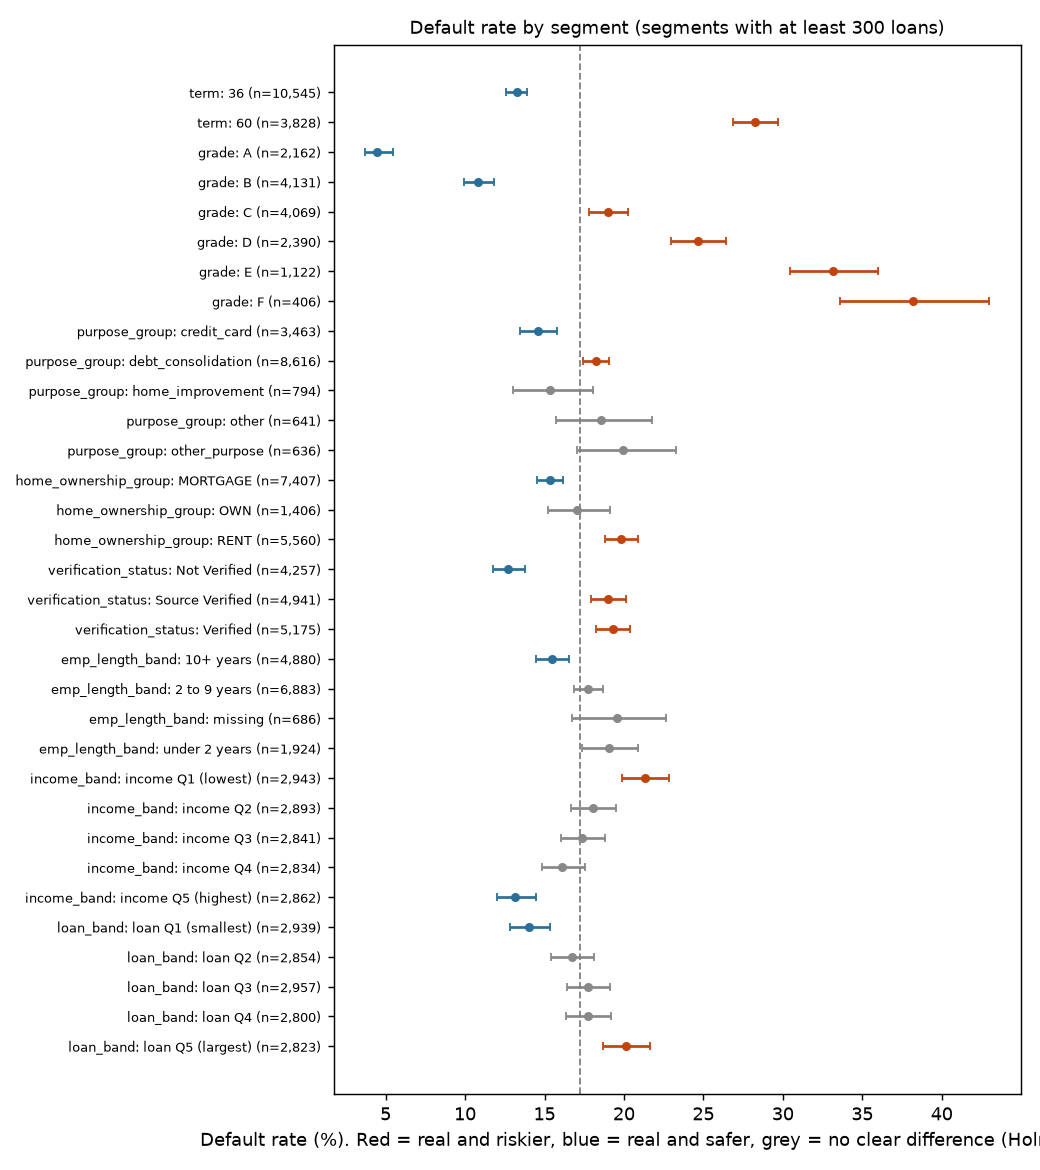

In [9]:
states = seg[seg.segment.str.contains("state")]
print(f"states: {len(states)} levels; {int(states.enough_loans.sum())} have at least 300 loans")
print(states.verdict.value_counts().to_string())
jobs = seg[seg.segment.str.contains("job")]
print("\njob groups:"); print(jobs.verdict.value_counts().to_string())
display(Image("reports/a6_deciles_and_segments/figures/default_rate_by_segment.png", width=900))

**Reading it.**
- **Term and grade are the strongest separators:** 36 months 13.2% against 60 months 28.3% (the 60-month figure is inflated by the in-progress bias in notebook 01); grades A to F run from 4.5% to 38.2%. Grade G (93 loans, 48.4%) is **too few to say**: its interval is wide.
- **Verification is not a safety badge:** unverified 12.7%, verified 19.3% (the platform's choice of whom to check).
- **State and job group mostly show no clear difference.** No state with at least 300 loans differs significantly from the rest after correction, and 10 of 11 job groups show no clear difference (only professional and technical, 14.1%, is safer). The small states are labelled "too few loans to say" rather than ranked. This matters for the fairness discussion below.

## 4. What do the factors add beyond the platform's grade? (bullet 2)
The grade is the platform's own risk rating, so a fair question is whether our factors know anything it doesn't. We measure on later loans (time-ordered folds before 2015):

             inputs    auc  auc_ci_low  auc_ci_high  gain_over_sub_grade
    sub-grade alone 0.6973      0.6777       0.7169               0.0000
      factors alone 0.6510      0.6320       0.6677              -0.0463
sub-grade + factors 0.7058      0.6866       0.7240               0.0084

the gain from adding the factors to the sub-grade, per fold, with 95% interval:
  fold  auc_gain  ci_low  ci_high
fold 1    0.0098 -0.0029   0.0211
fold 2    0.0071 -0.0024   0.0161

within a grade band, default rate of the lowest vs highest third of loans ranked by the factors:
grade_band  loans_per_group  rate_lowest_third  ci_low_1  ci_high_1  rate_highest_third  ci_low_2  ci_high_2  p_value
       A-B              725             0.0772    0.0600     0.0990              0.1324    0.1097     0.1590   0.0006
         C              467             0.1413    0.1127     0.1759              0.2575    0.2199     0.2991   0.0000
       D-G              485             0.2619    0.2247     0.3027      

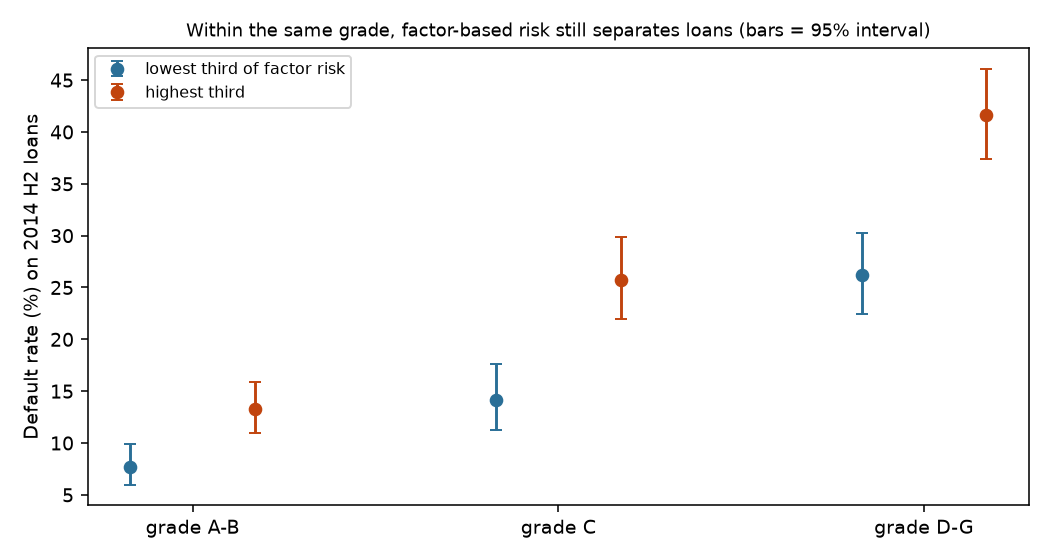

In [10]:
tb = "reports/a6_factors_vs_grade/tables/"
print(pd.read_csv(tb + "auc_grade_vs_factors.csv").round(4).to_string(index=False))
print("\nthe gain from adding the factors to the sub-grade, per fold, with 95% interval:")
print(pd.read_csv(tb + "paired_gain_from_factors.csv").round(4).to_string(index=False))
print("\nwithin a grade band, default rate of the lowest vs highest third of loans ranked by the factors:")
print(pd.read_csv(tb + "within_grade_separation.csv").round(4).to_string(index=False))
print("\ncorrelation of each factor with the sub-grade:")
print(pd.read_csv(tb + "factor_correlation_with_grade.csv").round(3).to_string(index=False))
display(Image("reports/a6_factors_vs_grade/figures/within_grade_separation.png", width=700))

**Reading it.**
- **Overall ranking:** the sub-grade alone scores AUC 0.697, the factors alone 0.651, together 0.706. The paired gain from adding the factors is about +0.010 and +0.007 in the two folds, but **the intervals touch zero**, so a better overall ranking is *not proven*.
- **Within a grade band the factors do separate loans clearly,** with non-overlapping intervals: in grades A-B the default rate is 7.7% for the lowest third of loans by factor risk against 13.2% for the highest; in C, 14.1% against 25.8%; in D-G, 26.2% against 41.7%. So the factors carry risk information that the grade does not fully use.
- **But the grade already captures most of the ranking,** and the factors partly overlap with it (utilisation 0.33, recent account opening 0.27), so the net gain is small.

**Conclusion:** the factors are an *explanation and a cross-check*, not a replacement for the grade. This is the honest answer to "what do they add?": a modest amount of extra information, not a better score by itself.

## 5. Could `zip_code` or `addr_state` act as a proxy for protected characteristics? (bullet 3)
The data holds no race, sex or age, so a proxy **cannot be measured directly, and that is the problem, not a reassurance.** In the United States, location is strongly tied to the racial, ethnic and age make-up of neighbourhoods, so a model that uses it can reproduce those differences without ever seeing them. What the data can tell us:

                                      measure   value
                                        loans 14373.0
                              distinct states    47.0
                distinct 3-digit zip prefixes   803.0
                  median loans per zip prefix    10.0
         zip prefixes with under 30 loans (%)    82.2
loans in zip prefixes with under 30 loans (%)    43.5

(live check) 803 zip prefixes, median 10 loans each, 82% of prefixes under 30 loans

state and income / default:
                                                   measure        value
                            states with at least 300 loans 1.600000e+01
share of income variation explained by state (eta squared) 7.974000e-03
                 Kruskal-Wallis p, income differs by state 7.277000e-23
                              median income, highest state 7.500000e+04
                               median income, lowest state 5.900000e+04
                               default rate, highest state 2.000000e-01
    

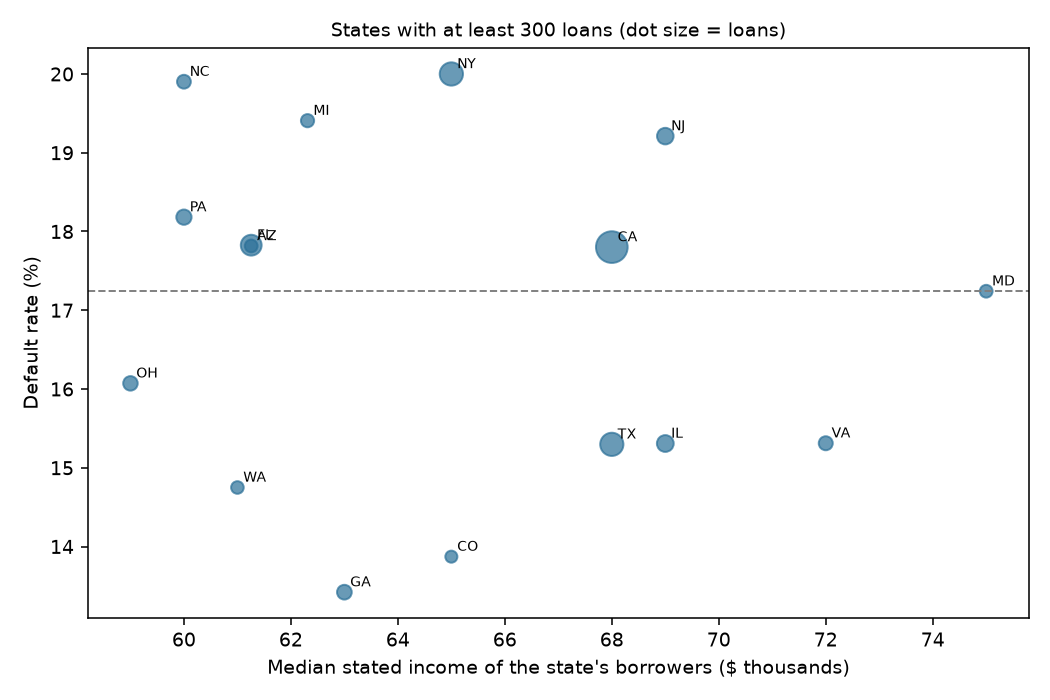

In [11]:
tb = "reports/a6_location_proxy/tables/"
print(pd.read_csv(tb + "location_sparsity.csv").to_string(index=False))
prefix_counts = fit.zip_code.value_counts()
print(f"\n(live check) {fit.zip_code.nunique()} zip prefixes, median {int(prefix_counts.median())} loans each, {100 * (prefix_counts < 30).mean():.0f}% of prefixes under 30 loans")
print("\nstate and income / default:")
print(pd.read_csv(tb + "state_income_and_risk_summary.csv").to_string(index=False))
print("\nwhat adding state to a model does (AUC on later loans):")
print(pd.read_csv(tb + "what_state_adds_to_a_model.csv").round(4).to_string(index=False))
display(Image("reports/a6_location_proxy/figures/state_income_vs_default.png", width=700))

**Reading it.**
- **Too sparse to use:** about 800 distinct 3-digit zip prefixes with a median of 10 loans each; 82% of prefixes (44% of loans) have under 30 loans.
- **It carries a little socio-economic signal:** state explains under 1% of the variation in income (small, but not chance), with median incomes from $59k to $75k across states.
- **It adds nothing to predictions, and hurts:** adding state lowers the AUC on later loans in both folds (-0.009 and -0.007; the intervals exclude zero).
- **Default does not differ reliably by state** (section 3).

**Recommendation.** **Do not use `zip_code` at all. Do not use `addr_state` as a model input.** Keep state **for monitoring only**: compare approval, default and calibration by state and region (Part B does this), where a gap would be a warning to investigate. With demographic data, which is not available here, a proper disparate-impact test would be the next step. Because location is sparse, uninformative and risky, the model gives up nothing by excluding it.

## 6. How training only on accepted loans limits the findings (bullet 4)

In [12]:
print(f"lowest FICO score in the data: {int(ds.fico_range_low.min())}; loans below 680: {(ds.fico_range_low < 680).mean():.0%}; below 660: {int((ds.fico_range_low < 660).sum())}")

lowest FICO score in the data: 660; loans below 680: 36%; below 660: 0


Every loan here was approved by the platform and then ran to a final outcome, so the model learns the default rate **among applicants the platform had already chosen to accept**, not among everyone who applies. People the platform declined, who are likely riskier, never appear: no borrower in the data has a FICO score below 660, so nothing is known about lower scores, and the model can say nothing reliable there. The relationships we measure are probably **weaker** than they would be in the full applicant pool, because the platform's own acceptance rules already removed the extremes of the fields they used (score, `dti`, income), and a model trained here will look better calibrated and more stable than it would on the people who actually apply. PD thresholds set on these default rates are therefore valid only for applicants who resemble accepted ones. Declined applicants' outcomes cannot be observed, so the remedies are partial: restrict decisions to the range the data covers, monitor the applicant mix, and, if the platform keeps declined applications, use reject-inference methods or small controlled approvals of borderline applicants to learn what happens outside the accepted region. The label has a second selection effect (notebook 01): unfinished loans were removed, which inflates recent 60-month default rates.

## Summary: what the brief asked, and where it is answered

| Brief item | Answered in |
|---|---|
| PSI, 2013 vs 2014, key fields and factor scores, flag drift | section 1 |
| Default rate by factor-score decile with 95% intervals and a significance test | section 2 |
| Default rate by segment with intervals, tests, and a rule against small groups | section 3 |
| What the factors add beyond the platform's grade | section 4 |
| Location as a proxy for protected characteristics, and a recommendation | section 5 |
| Accepted-only bias, in one paragraph | section 6 |